# HW4: Ridge stock-return model and a monthly top-N backtest


How to run: 
1. run `uv sync --locked` 
2. put `equities_top2000.duckdb`  into `Lectures/modeling/data/`
3. run all cells or optionally set `DATABASE = "equities_class.duckdb"` in the config cell for a quick run on the 30-stock class extract

In [1]:
import sys
import time
import warnings
from dataclasses import dataclass, asdict
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.linear_model import Ridge

course_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
modeling_dir = course_root / "Lectures/modeling"
if str(modeling_dir) not in sys.path:
    sys.path.insert(0, str(modeling_dir))
from course_data import (FEATURES, load_data, load_membership, price_features, financial_events,
                         join_financials, apply_membership, make_labels, date_folds,
                         make_pipeline, prediction_metrics)

pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (10, 5)

## Configuration


In [2]:
DATABASE = "equities_top2000.duckdb"          
DB_PATH = modeling_dir / "data" / DATABASE
HERE = course_root / "Homeworks/HW4/Genrikh_Kuznetsov"
OUTPUTS = HERE / "outputs"                     
RESULTS = HERE / "results"                     
OUTPUTS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

CONFIG = {
    "history_end": "2026-09-30",
    "panel_start": "2009-01-01",      
    "train_start": "2010-01-01",
    "dev_end": "2015-12-31",
    "validation_years": [2012, 2013, 2014, 2015],
    "alpha_grid": [100, 10_000, 1_000_000],
    "top_n_grid": [10, 20, 50],
    "test_start": "2016-04-01",
    "test_end": "2026-09-30",
    "holding_days": 90,
    "cohort_fraction": 1 / 3,          
    "initial_cash": 1_000_000,
    "fee_bps": 5,                      
    "risk_free": 0.02,
    "target_clip": (0.01, 0.99),       
    "max_stale_sessions": 5,
}
CONFIG

{'history_end': '2026-09-30',
 'panel_start': '2009-01-01',
 'train_start': '2010-01-01',
 'dev_end': '2015-12-31',
 'validation_years': [2012, 2013, 2014, 2015],
 'alpha_grid': [100, 10000, 1000000],
 'top_n_grid': [10, 20, 50],
 'test_start': '2016-04-01',
 'test_end': '2026-09-30',
 'holding_days': 90,
 'cohort_fraction': 0.3333333333333333,
 'initial_cash': 1000000,
 'fee_bps': 5,
 'risk_free': 0.02,
 'target_clip': (0.01, 0.99),
 'max_stale_sessions': 5}

## 1. Load the data and build features

There are 3,849 stocks and ~15.8 million price rows, so I use the lecture functions:

1. `load_data(symbols=batch)`: read-only SQL, quarantines the known bad rows (BHRB zero prices, off-calendar dates).
2. `price_features`: momentum (21, 63, 252-skip-21 sessions), 63-day volatility, 252-day drawdown, on the market calendar without filling gaps.
3. `financial_events` + `join_financials`: quarterly ratios usable only from filing date + 1 day, blanked once the fiscal period is > 550 days old.
4. `apply_membership`: `eligible` is true only if the stock is in the quarterly top-2,000 list of the next-session entry quarter and has 63 clean daily returns.
5. `make_labels`: target = adjusted close at the first quote on/after entry + 90 calendar days ÷ adjusted close at entry (the next session) − 1. `label_end` records when that outcome becomes known.

All stocks stay in the panel, including inactive ones. I only drop pre-2009 rows after the features are computed (they were needed as look-back history).

In [3]:
KEEP = ["date", "symbol", "eligible", "target", "label_end"] + FEATURES


def build_panel(db_path, end, start, batch_size=400):
    with duckdb.connect(str(db_path), read_only=True) as con:
        symbols = [r[0] for r in con.execute("SELECT symbol FROM universe ORDER BY symbol").fetchall()]
    membership = load_membership(db_path, end=end)
    parts = []
    for i in range(0, len(symbols), batch_size):
        batch = symbols[i:i + batch_size]
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            prices, fundamentals, universe, benchmark = load_data(db_path, end=end, symbols=batch)
        for w in caught:
            print(f"  batch {i // batch_size}: {w.message}")
        p = price_features(prices, benchmark.date)
        p = join_financials(p, financial_events(fundamentals), universe)
        p = apply_membership(p, membership, benchmark.date)
        p = make_labels(p, prices, benchmark.date)
        parts.append(p.loc[p.date.ge(start), KEEP])
    panel = pd.concat(parts, ignore_index=True).sort_values(["date", "symbol"]).reset_index(drop=True)
    num = panel.select_dtypes("float64").columns
    panel[num] = panel[num].astype("float32")      
    panel["target"] = panel.target.astype("float64")
    return panel


panel_file = OUTPUTS / f"panel_{DB_PATH.stem}.parquet"
t0 = time.time()
if panel_file.exists():
    panel = pd.read_parquet(panel_file)
    print("Loaded cached panel", panel_file.name)
else:
    panel = build_panel(DB_PATH, CONFIG["history_end"], CONFIG["panel_start"])
    panel.to_parquet(panel_file)
print(f"panel: {len(panel):,} rows, {panel.symbol.nunique():,} symbols, "
      f"{panel.memory_usage(deep=True).sum() / 1e9:.2f} GB, {time.time() - t0:.0f}s")

Loaded cached panel panel_equities_top2000.parquet


panel: 12,065,452 rows, 3,848 symbols, 2.26 GB, 6s


For the backtester I also need daily adjusted closes for every symbol and the benchmark. I apply the same quarantine rules as `load_data` (positive, finite, on the market calendar).

In [4]:
with duckdb.connect(str(DB_PATH), read_only=True) as con:
    benchmark = con.execute("SELECT date, adj_close FROM benchmark WHERE date <= ? ORDER BY date",
                            [CONFIG["history_end"]]).fetchdf()
    raw_prices = con.execute("""SELECT symbol, date, adj_close FROM prices
                                WHERE date >= '2011-01-01' AND date <= ?""", [CONFIG["history_end"]]).fetchdf()
    sectors = con.execute("SELECT symbol, coalesce(sector, 'Unknown') AS sector FROM universe").fetchdf().set_index("symbol").sector
benchmark["date"] = pd.to_datetime(benchmark.date)
raw_prices["date"] = pd.to_datetime(raw_prices.date)
calendar = pd.DatetimeIndex(benchmark.date)

ok = np.isfinite(raw_prices.adj_close) & raw_prices.adj_close.gt(0) & raw_prices.date.isin(calendar)
print("Quarantined price rows (non-positive or off-calendar) since 2011:", int((~ok).sum()))
quotes = (raw_prices.loc[ok].pivot(index="date", columns="symbol", values="adj_close")
          .reindex(calendar[calendar >= "2011-01-01"]))
bench_px = benchmark.set_index("date").adj_close
print("quotes matrix:", quotes.shape)

Quarantined price rows (non-positive or off-calendar) since 2011: 27


quotes matrix: (3959, 3847)


Looking at the data

In [5]:
eligible = panel.loc[panel.eligible]
summary = pd.Series({
    "eligible rows": len(eligible),
    "eligible rows with a known target": int(eligible.target.notna().sum()),
    "avg eligible stocks per day (2016+)": eligible.loc[eligible.date.ge("2016")].groupby("date").size().mean(),
    "target 1% quantile": eligible.target.quantile(.01),
    "target median": eligible.target.median(),
    "target 99% quantile": eligible.target.quantile(.99),
    "target max": eligible.target.max(),
})
display(summary.to_frame("value"))
display(eligible[FEATURES[:-1]].describe().T[["count", "mean", "50%", "min", "max"]])
del eligible

,value
eligible rows,8.787559e+06
eligible rows with a known target,8.627803e+06
avg eligible stocks per day (2016+),1.982265e+03
target 1% quantile,-4.784748e-01
target median,2.759740e-02
target 99% quantile,7.686957e-01
target max,1.427073e+05


,count,mean,50%,min,max
momentum_21,8787559.0,2.013699e-01,0.009763,-9.999948e-01,140468.968750
momentum_63,8787559.0,2.322346e-01,0.029011,-9.999923e-01,142707.328125
momentum_252_21,8542457.0,3.979207e-01,0.094787,-9.999918e-01,100668.656250
volatility_63,8787559.0,7.733348e+00,0.326602,0.000000e+00,271538.500000
drawdown_252,8526368.0,-1.802318e-01,-0.124664,-9.999956e-01,0.000000
net_margin,8595702.0,-1.809054e+09,0.069554,-3.110000e+14,8036.194824
operating_roa,8768497.0,-1.047114e+00,0.013598,-1.460142e+05,82068.000000
debt_to_assets,8767641.0,1.253888e+01,0.244406,0.000000e+00,389447.750000
cash_to_assets,8768807.0,3.786968e+01,0.065237,-8.083930e-01,995482.562500
fcf_to_assets,8746411.0,1.891059e+00,0.008275,-1.374472e+04,257024.453125


## 2. Model: choose the Ridge penalty on development data

The lectures showed that 90-day stock returns are very noisy, so a simple, heavily regularized linear model is a sensible baseline as it is fast, hard to overfit, and its coefficients are interpretable. It also scales to millions of rows, which matters for the full universe.

For validation expanding-window: one fold per year 2012–2015 (`date_folds`). Each fold's model is fitted immediately before the validation year, using only rows whose `label_end` is before the first validation signal, so no training outcome overlaps the validation period. All stocks on a date stay together. I judge models by mean daily rank IC because the strategy only uses the ranking of stocks, not the forecast's level.

In [6]:
def training_target(rows, kind):
    """Target used to FIT the model. Uses only the training rows passed in."""
    if kind == "raw":
        lo, hi = rows.target.quantile(list(CONFIG["target_clip"]))
        return rows.target.clip(lo, hi)
    if kind == "rank":
        return rows.target.groupby(rows.date).rank(pct=True) - 0.5
    raise ValueError(kind)


def new_model(alpha):
    return make_pipeline(Ridge(alpha=alpha))     


dev_end = pd.Timestamp(CONFIG["dev_end"])
development = panel.loc[panel.eligible & panel.date.ge(CONFIG["train_start"]) & panel.date.le(dev_end)
                        & panel.target.notna() & panel.label_end.le(dev_end)].reset_index(drop=True)
folds = date_folds(development, validation_years=CONFIG["validation_years"], train_start=CONFIG["train_start"])
print(f"development rows: {len(development):,}")

rows = []
t0 = time.time()
for kind in ["raw", "rank"]:
    for alpha in CONFIG["alpha_grid"]:
        for year, (tr, va) in zip(CONFIG["validation_years"], folds):
            train_rows, va_rows = development.iloc[tr], development.iloc[va]
            m = new_model(alpha).fit(train_rows[FEATURES], training_target(train_rows, kind))
            metrics = prediction_metrics(va_rows, m.predict(va_rows[FEATURES]))
            rows.append({"target": kind, "alpha": alpha, "year": year, "train_rows": len(tr),
                         "rank_IC": metrics.mean_daily_rank_IC})
cv = pd.DataFrame(rows)
print(f"{len(rows)} fits in {time.time() - t0:.0f}s")
cv_table = cv.pivot_table(index=["target", "alpha"], columns="year", values="rank_IC")
cv_table["mean"] = cv_table.mean(axis=1)
display(cv_table.round(4))
cv_table.to_csv(RESULTS / "validation_rank_ic.csv")
TARGET_KIND, ALPHA = cv_table["mean"].idxmax()
print(f"Chosen: target={TARGET_KIND}, alpha={ALPHA:g}")

development rows: 2,843,985


24 fits in 133s


year              2012    2013    2014    2015    mean
target alpha                                          
rank   100      0.0479 -0.0473  0.0479  0.0532  0.0254
       10000    0.0493 -0.0489  0.0499  0.0514  0.0254
       1000000  0.0589 -0.0549  0.0924  0.0405  0.0342
raw    100     -0.0055 -0.0311  0.0221 -0.0366 -0.0128
       10000   -0.0043 -0.0306  0.0232 -0.0391 -0.0127
       1000000  0.0148 -0.0309  0.0347 -0.0646 -0.0115

Chosen: target=rank, alpha=1e+06


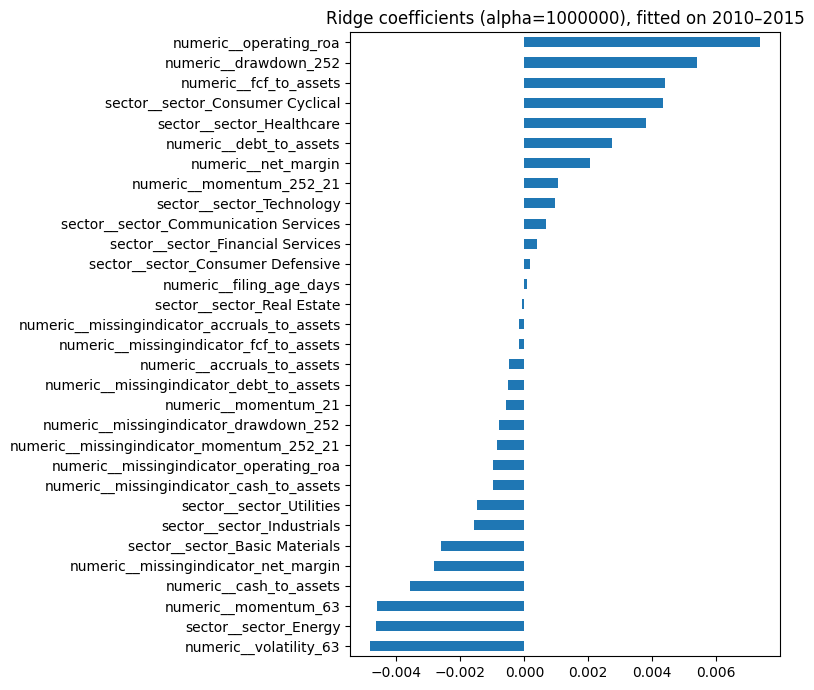

In [7]:
dev_model = new_model(ALPHA).fit(development[FEATURES], training_target(development, TARGET_KIND))
coef = pd.Series(dev_model.named_steps["model"].coef_,
                 index=dev_model.named_steps["preprocess"].get_feature_names_out()).sort_values()
coef.plot.barh(figsize=(8, 7), title=f"Ridge coefficients (alpha={ALPHA}), fitted on 2010–2015")
plt.tight_layout()
plt.show()

## 3. My backtester

Two small classes:

* `Account` owns cash, open lots, and the trade log. `buy` takes a fee-inclusive dollar budget, so a $10,000 budget buys $9,995 of stock + $5 fee at 5 bps. `sell` closes a whole lot and books realized PnL. It refuses to spend cash it does not have.
* `Backtester` walks through market sessions. On each session `day`:
  1. The decision for `day` uses only information from the previous session's close (`signal_date`): the model scores from that date and the account's cash/NAV after that close. Fill prices for `day` are not known yet.
  2. Lots whose 90-calendar-day maturity has arrived are sold at `day`'s close (if a lot's stock has no quote, it is sold at its next available close).
  3. If `day` is the first session of a month, buy the `top_n` highest-scored eligible stocks at `day`'s close, splitting a budget of `min(cash, cohort_fraction × NAV)` measured at the signal close. Because cash can only grow between the signal close and the fill (from sales), the same cash can never be spent twice.
  4. Mark every open lot at its latest observed close and record cash, holdings, and NAV.

Assumptions: prices are adjusted closes so returns already include dividends, 5 bps cost per side, cash earns 0%, no leverage, long only.

A buy is rejected if the stock has no quote on the fill day. An open lot without a quote keeps its last observed close and is flagged stale. If that lasts more than 5 sessions it is flagged as an unresolved price gap: I do not invent a sale.

In [8]:
@dataclass
class Lot:
    """One purchase; every lot has its own cost basis and maturity."""
    lot_id: int
    symbol: str
    units: float
    signal_date: pd.Timestamp
    entry_date: pd.Timestamp
    entry_price: float
    entry_fee: float
    due_date: pd.Timestamp


class Account:
    """Cash, open lots, and the trade log. Knows nothing about strategies."""

    def __init__(self, initial_cash=1_000_000, fee_bps=5):
        self.initial_cash = float(initial_cash)
        self.cash = float(initial_cash)
        self.fee_rate = fee_bps / 10_000
        self.lots = {}
        self.trades = []
        self.realized_pnl = 0.0
        self._next_id = 0

    def buy(self, symbol, budget, price, date, signal_date, holding_days):
        """Spend `budget` dollars INCLUDING the fee, at `price`."""
        if not (signal_date < date):
            raise ValueError("A decision must be made before its fill date")
        if not (np.isfinite(price) and price > 0 and budget > 0):
            raise ValueError("Need a positive price and budget")
        units = budget / (price * (1 + self.fee_rate))
        notional = units * price
        fee = notional * self.fee_rate
        if notional + fee > self.cash + 1e-6:
            raise ValueError(f"Not enough cash to buy {symbol} on {date.date()}")
        self.cash -= notional + fee
        lot = Lot(self._next_id, symbol, units, signal_date, date, price, fee,
                  date + pd.Timedelta(days=holding_days))
        self.lots[lot.lot_id] = lot
        self._next_id += 1
        self._log(lot, "BUY", date, price, fee, -(notional + fee), 0.0)
        return lot

    def sell(self, lot_id, price, date):
        """Sell a whole lot at `price`; realized PnL includes both fees."""
        lot = self.lots[lot_id]
        if date < lot.due_date or not (np.isfinite(price) and price > 0):
            raise ValueError("Lots are sold at a valid price on/after maturity")
        del self.lots[lot_id]
        notional = lot.units * price
        fee = notional * self.fee_rate
        pnl = notional - fee - (lot.units * lot.entry_price + lot.entry_fee)
        self.cash += notional - fee
        self.realized_pnl += pnl
        self._log(lot, "SELL", date, price, fee, notional - fee, pnl)
        return pnl

    def holdings_value(self, marks):
        return sum(lot.units * marks[lot.symbol] for lot in self.lots.values())

    def _log(self, lot, side, date, price, fee, cash_change, pnl):
        self.trades.append(dict(date=date, side=side, lot_id=lot.lot_id, symbol=lot.symbol,
                                signal_date=lot.signal_date, entry_date=lot.entry_date,
                                due_date=lot.due_date, price=price, units=lot.units,
                                notional=lot.units * price, fee=fee,
                                cash_change=cash_change, realized_pnl=pnl))


class Backtester:
    """Daily loop: decide at the previous close, trade at today's close, mark to market."""

    def __init__(self, quotes, scores, top_n=20, cohort_fraction=1 / 3, holding_days=90,
                 initial_cash=1_000_000, fee_bps=5, max_stale_sessions=5):
        self.quotes = quotes                      
        self.scores = scores                      
        self.top_n = top_n
        self.cohort_fraction = cohort_fraction
        self.holding_days = holding_days
        self.max_stale = max_stale_sessions
        self.account = Account(initial_cash, fee_bps)

    def run(self, start, end):
        cal = self.quotes.index
        days = cal[(cal >= pd.Timestamp(start)) & (cal <= pd.Timestamp(end))]
        acct = self.account
        last_mark, last_seen = {}, {}          
        events, history = [], []
        first = cal.get_loc(days[0])
        history.append(dict(date=cal[first - 1], cash=acct.cash, holdings=0.0, nav=acct.cash, open_lots=0,
                            buys=0, sells=0, stale_lots=0))
        signal_cash, signal_nav = acct.cash, acct.cash   
        for day in days:
            i = cal.get_loc(day)
            signal_date = cal[i - 1]
            today = self.quotes.iloc[i]
            observed = today[today.notna()]
            # Update marks for the stocks we hold (new purchases are marked when bought).
            held = {lot.symbol for lot in acct.lots.values()}
            for sym in held:
                px = today.get(sym, np.nan)
                if np.isfinite(px):
                    last_mark[sym], last_seen[sym] = px, i

            # 1) planned at the signal close: which stocks to buy today (first session of a month)
            orders = pd.Series(dtype=float)
            if day.month != signal_date.month:
                s = self.scores.get(signal_date)
                if s is not None and len(s):
                    picks = s.sort_values(ascending=False, kind="stable").head(self.top_n)
                    budget = min(signal_cash, self.cohort_fraction * signal_nav)
                    if budget > 1.0:              # nothing to spend if all cash is still in open lots
                        orders = pd.Series(budget / len(picks), index=picks.index)
                else:
                    events.append(dict(date=day, symbol=None, event="no_scores_for_signal"))

            # 2) sell matured lots at today's close (or at the first later close that exists)
            n_sells = 0
            for lot in list(acct.lots.values()):
                if day >= lot.due_date and lot.symbol in observed.index:
                    acct.sell(lot.lot_id, observed[lot.symbol], day)
                    n_sells += 1

            # 3) buy at today's close; the budget was fixed at the signal close
            n_buys = 0
            for sym, budget in orders.items():
                if sym not in observed.index:
                    events.append(dict(date=day, symbol=sym, event="buy_rejected_no_quote"))
                    continue
                acct.buy(sym, budget, observed[sym], day, signal_date, self.holding_days)
                last_mark[sym], last_seen[sym] = observed[sym], i
                n_buys += 1
            if acct.cash < -1e-6:
                raise AssertionError("Cash went negative")

            # 4) mark to market; flag lots without a fresh quote
            stale = 0
            for sym in {lot.symbol for lot in acct.lots.values()}:
                gap = i - last_seen[sym]
                if gap > 0:
                    stale += 1
                    if gap == self.max_stale + 1:
                        events.append(dict(date=day, symbol=sym, event="unresolved_price_gap"))
            holdings = acct.holdings_value(last_mark)
            nav = acct.cash + holdings
            history.append(dict(date=day, cash=acct.cash, holdings=holdings, nav=nav,
                                open_lots=len(acct.lots), buys=n_buys, sells=n_sells, stale_lots=stale))
            signal_cash, signal_nav = acct.cash, nav
        self.last_mark, self.last_seen, self.end_index = last_mark, last_seen, cal.get_loc(days[-1])
        self.history = pd.DataFrame(history).set_index("date")
        self.trades = pd.DataFrame(acct.trades)
        self.events = pd.DataFrame(events, columns=["date", "symbol", "event"])
        self.open_lots = pd.DataFrame([asdict(l) for l in acct.lots.values()], columns=list(Lot.__dataclass_fields__))
        if len(self.open_lots):
            self.open_lots["last_mark"] = self.open_lots.symbol.map(last_mark)
            self.open_lots["market_value"] = self.open_lots.units * self.open_lots.last_mark
            self.open_lots["last_quote"] = self.open_lots.symbol.map(lambda s: cal[last_seen[s]])
        return self.history


def performance(nav, annual_rf=0.02):
    """CAGR on calendar time (365.25 days), Sharpe on daily returns (252 sessions)."""
    r = nav.pct_change().dropna()
    years = (nav.index[-1] - nav.index[0]).days / 365.25
    excess = r - ((1 + annual_rf) ** (1 / 252) - 1)
    return pd.Series({
        "start_value": nav.iloc[0],
        "final_value": nav.iloc[-1],
        "total_return": nav.iloc[-1] / nav.iloc[0] - 1,
        "CAGR": (nav.iloc[-1] / nav.iloc[0]) ** (1 / years) - 1,
        "max_drawdown": (nav / nav.cummax() - 1).min(),
        "annual_volatility": r.std() * np.sqrt(252),
        "Sharpe": np.sqrt(252) * excess.mean() / r.std(),
    })

### 3. Checks

A tiny made-up market with two stocks, A and B, over a few sessions, with a 4-day holding period so the lot matures quickly. Fees are 10 bps, `top_n=1`, cohort fraction 1/2. The test checks:

* the fee-inclusive purchase, the cash balance, and the realized PnL against numbers computed by hand,
* that the decision uses the previous close (scores dated the signal date) and fills at the next close,
* that a lot whose stock has no quote on its maturity date is sold on the next quoted session,
* that cash + holdings = NAV every day, and that cash rebuilt from the trade log matches.

In [9]:
toy_dates = pd.DatetimeIndex(["2020-01-30", "2020-01-31", "2020-02-03", "2020-02-04", "2020-02-05",
                              "2020-02-06", "2020-02-07", "2020-02-10", "2020-02-11"])
toy_quotes = pd.DataFrame({"A": [10, 10, 11, 12, 12, 13, np.nan, 14, 14],
                           "B": [50, 50, 50, 50, 50, 50, 50, 50, 50]}, index=toy_dates, dtype=float)
# Scores known at the 2020-01-31 close -> buy at the 2020-02-03 close (first session of February).
toy_scores = {pd.Timestamp("2020-01-31"): pd.Series({"A": 0.9, "B": 0.1})}
toy = Backtester(toy_quotes, toy_scores, top_n=1, cohort_fraction=0.5, holding_days=4,
                 initial_cash=1_000, fee_bps=10)
toy_hist = toy.run("2020-01-31", "2020-02-11")
display(toy.trades[["date", "side", "symbol", "signal_date", "due_date", "price", "units", "fee", "cash_change", "realized_pnl"]])
display(toy_hist)

# Hand calculation:
# Budget = min(cash 1000, 0.5 * NAV 1000) = 500 incl. fee. Units = 500 / (11 * 1.001).
units = 500 / (11 * 1.001)
buy_fee = units * 11 * 0.001
assert np.isclose(toy.trades.loc[0, "units"], units) and np.isclose(buy_fee + units * 11, 500)
buy = toy.trades.iloc[0]
assert buy.date == pd.Timestamp("2020-02-03") and buy.signal_date == pd.Timestamp("2020-01-31")
# Due 2020-02-07, but A has no quote that day -> sold at the next quoted close, 2020-02-10 at 14.
assert buy.due_date == pd.Timestamp("2020-02-07")
sell = toy.trades.iloc[1]
assert sell.date == pd.Timestamp("2020-02-10") and sell.price == 14
sell_fee = units * 14 * 0.001
assert np.isclose(sell.realized_pnl, units * 14 - sell_fee - 500)
assert np.isclose(toy.account.cash, 1000 - 500 + units * 14 - sell_fee)
# NAV on 2020-02-07 uses A's stale 2020-02-06 close (13) and flags it.
assert np.isclose(toy_hist.loc["2020-02-07", "nav"], 500 + units * 13) and toy_hist.loc["2020-02-07", "stale_lots"] == 1
assert np.allclose(toy_hist.cash + toy_hist.holdings, toy_hist.nav)
print(f"Hand check passed: bought {units:.4f} units of A at 11 for $500 incl. ${buy_fee:.4f} fee; "
      f"sold at 14 on 2020-02-10 for PnL ${sell.realized_pnl:.2f}; final cash ${toy.account.cash:.2f}")

,date,side,symbol,signal_date,due_date,price,units,fee,cash_change,realized_pnl
0,2020-02-03,BUY,A,2020-01-31,2020-02-07,11.0,45.409136,0.499500,-500.000000,0.000000
1,2020-02-10,SELL,A,2020-01-31,2020-02-07,14.0,45.409136,0.635728,635.092181,135.092181


,cash,holdings,nav,open_lots,buys,sells,stale_lots
date,,,,,,,
2020-01-30,1000.000000,0.000000,1000.000000,0,0,0,0
2020-01-31,1000.000000,0.000000,1000.000000,0,0,0,0
2020-02-03,500.000000,499.500500,999.500500,1,1,0,0
2020-02-04,500.000000,544.909636,1044.909636,1,0,0,0
2020-02-05,500.000000,544.909636,1044.909636,1,0,0,0
2020-02-06,500.000000,590.318772,1090.318772,1,0,0,0
2020-02-07,500.000000,590.318772,1090.318772,1,0,0,1
2020-02-10,1135.092181,0.000000,1135.092181,0,0,1,0
2020-02-11,1135.092181,0.000000,1135.092181,0,0,0,0


Hand check passed: bought 45.4091 units of A at 11 for $500 incl. $0.4995 fee; sold at 14 on 2020-02-10 for PnL $135.09; final cash $1135.09


Two more edge cases: a buy order for a stock with no quote on the fill day is rejected and logged (no invented fill), and the account refuses to spend more cash than it has.

In [10]:
toy2_quotes = toy_quotes.copy()
toy2_quotes.loc["2020-02-03", "A"] = np.nan
toy2 = Backtester(toy2_quotes, toy_scores, top_n=1, cohort_fraction=0.5, holding_days=4, initial_cash=1_000, fee_bps=10)
toy2.run("2020-01-31", "2020-02-11")
assert toy2.trades.empty and toy2.events.event.eq("buy_rejected_no_quote").any()
display(toy2.events)

acct = Account(initial_cash=100, fee_bps=10)
try:
    acct.buy("A", 100.01, 10.0, pd.Timestamp("2020-02-03"), pd.Timestamp("2020-01-31"), 90)
    raise AssertionError("should have refused")
except ValueError as e:
    print("Refused as expected:", e)

,date,symbol,event
0,2020-02-03,A,buy_rejected_no_quote


Refused as expected: Not enough cash to buy A on 2020-02-03


## 4. Choose the strategy on development data (2012–2015)

To choose how many stocks to buy each month, I need out-of-sample forecasts for the development years. For each year 2012–2015 I fit the chosen Ridge on rows whose labels matured before that year began, then score every eligible stock at each month-end signal close of that year. Then I backtest `top_n` in {10, 20, 50} from 2012 to 2015 and pick the one with the best Sharpe.

In [11]:
is_month_end = pd.Series(calendar.month, index=calendar).shift(-1).ne(calendar.month).to_numpy()
month_end_signals = calendar[is_month_end][:-1]          


def score_rows(model, rows, fit_date):
    out = rows[["date", "symbol"]].copy()
    out["score"] = model.predict(rows[FEATURES])
    out["fit_date"] = fit_date
    return out


def fit_and_score(fit_dates, score_end):
    """Walk forward: at each fit date use only matured labels, then score month-end signals until the next fit."""
    parts, audit = [], []
    bounds = list(fit_dates) + [pd.Timestamp(score_end) + pd.Timedelta(days=1)]
    for asof, nxt in zip(bounds[:-1], bounds[1:]):
        train = panel.loc[panel.eligible & panel.date.ge(CONFIG["train_start"]) & panel.date.lt(asof)
                          & panel.label_end.lt(asof) & panel.target.notna()]
        to_score = panel.loc[panel.eligible & panel.date.ge(asof) & panel.date.lt(nxt)
                             & panel.date.isin(month_end_signals)]
        model = new_model(ALPHA).fit(train[FEATURES], training_target(train, TARGET_KIND))
        parts.append(score_rows(model, to_score, asof))
        audit.append(dict(fit_date=asof, train_rows=len(train), last_train_signal=train.date.max(),
                          last_label_end=train.label_end.max(), first_scored=to_score.date.min(),
                          last_scored=to_score.date.max(), scored_rows=len(to_score)))
        assert train.label_end.max() < to_score.date.min(), "training outcome not yet known at the fit"
    return pd.concat(parts, ignore_index=True), pd.DataFrame(audit)


def to_score_dict(scores):
    return {d: g.set_index("symbol").score for d, g in scores.groupby("date")}


t0 = time.time()
# The fit for each development year happens at the last session before that year.
dev_fit_dates = [calendar[calendar < f"{y}-01-01"][-1] for y in CONFIG["validation_years"]]
dev_scores, dev_audit = fit_and_score(dev_fit_dates, CONFIG["dev_end"])
display(dev_audit)

dev_runs = {}
for n in CONFIG["top_n_grid"]:
    bt = Backtester(quotes, to_score_dict(dev_scores), top_n=n, cohort_fraction=CONFIG["cohort_fraction"],
                    holding_days=CONFIG["holding_days"], initial_cash=CONFIG["initial_cash"], fee_bps=CONFIG["fee_bps"])
    bt.run("2012-01-03", CONFIG["dev_end"])
    dev_runs[n] = bt
dev_bench = bench_px.loc[dev_runs[CONFIG["top_n_grid"][0]].history.index]
dev_table = pd.DataFrame({f"top {n}": performance(bt.history.nav, CONFIG["risk_free"]) for n, bt in dev_runs.items()})
dev_table["S&P 500 TR"] = performance(dev_bench / dev_bench.iloc[0] * CONFIG["initial_cash"], CONFIG["risk_free"])
display(dev_table.round(3))
TOP_N = int(max(CONFIG["top_n_grid"], key=lambda n: dev_table.loc["Sharpe", f"top {n}"]))
print(f"Chosen top_n: {TOP_N}   ({time.time() - t0:.0f}s)")

,fit_date,train_rows,last_train_signal,last_label_end,first_scored,last_scored,scored_rows
0,2011-12-30,844456,2011-09-29,2011-12-29,2011-12-30,2012-11-30,23713
1,2012-12-31,1340485,2012-09-27,2012-12-27,2012-12-31,2013-11-29,23808
2,2013-12-31,1838562,2013-09-30,2013-12-30,2013-12-31,2014-11-28,23843
3,2014-12-31,2339927,2014-09-30,2014-12-30,2014-12-31,2015-12-31,25868


,top 10,top 20,top 50,S&P 500 TR
start_value,1000000.000,1000000.000,1000000.000,1000000.000
final_value,1696117.120,1639335.866,1586323.051,1770127.933
total_return,0.696,0.639,0.586,0.770
CAGR,0.141,0.131,0.122,0.153
max_drawdown,-0.093,-0.090,-0.086,-0.120
annual_volatility,0.108,0.099,0.097,0.128
Sharpe,1.098,1.099,1.038,1.028


Chosen top_n: 20   (24s)


Retraining rule: refit Ridge with the fixed alpha after the close on the last session of every quarter, on all eligible rows since 2010 whose labels have already matured (an expanding window, like in lectures). Each fit scores the month-end signals until the next fit.

## 5. Final test: April 1, 2016 – September 30, 2026

The first fit is at the 2016-03-31 close and scores the signal for the first purchase on 2016-04-01. Fits continue through 2026-06-30, whose scores cover the last purchase on 2026-09-01.

In [12]:
t0 = time.time()
test_start, test_end = pd.Timestamp(CONFIG["test_start"]), pd.Timestamp(CONFIG["test_end"])
is_quarter_end = pd.Series(calendar.quarter, index=calendar).shift(-1).ne(calendar.quarter).to_numpy()
test_fit_dates = [d for d in calendar[is_quarter_end] if calendar[calendar < test_start][-1] <= d < test_end]
test_scores, test_audit = fit_and_score(test_fit_dates, "2026-08-31")
print(f"{len(test_fit_dates)} fits in {time.time() - t0:.0f}s")
display(test_audit.head(3))
display(test_audit.tail(2))
test_scores.to_parquet(OUTPUTS / "test_scores.parquet")

42 fits in 1193s


,fit_date,train_rows,last_train_signal,last_label_end,first_scored,last_scored,scored_rows
0,2016-03-31,2967493,2015-12-30,2016-03-30,2016-03-31,2016-05-31,5979
1,2016-06-30,3088825,2016-03-30,2016-06-29,2016-06-30,2016-08-31,5963
2,2016-09-30,3218050,2016-06-30,2016-09-29,2016-09-30,2016-11-30,5979


,fit_date,train_rows,last_train_signal,last_label_end,first_scored,last_scored,scored_rows
40,2026-03-31,7917910,2025-12-29,2026-03-30,2026-03-31,2026-05-29,5952
41,2026-06-30,8038367,2026-03-30,2026-06-29,2026-06-30,2026-08-31,5951


In [13]:
t0 = time.time()
bt = Backtester(quotes, to_score_dict(test_scores), top_n=TOP_N, cohort_fraction=CONFIG["cohort_fraction"],
                holding_days=CONFIG["holding_days"], initial_cash=CONFIG["initial_cash"],
                fee_bps=CONFIG["fee_bps"], max_stale_sessions=CONFIG["max_stale_sessions"])
hist = bt.run(test_start, test_end)
print(f"backtest: {time.time() - t0:.0f}s, {len(bt.trades):,} trades, {len(bt.open_lots)} lots open at the end")

# Benchmark: $1,000,000 in ^SP500TR at the first test close, held to the end.
hist["benchmark_nav"] = float(CONFIG["initial_cash"])
bench_days = hist.index[1:]
hist.loc[bench_days, "benchmark_nav"] = CONFIG["initial_cash"] * bench_px.loc[bench_days] / bench_px.loc[bench_days[0]]
display(hist.tail())

backtest: 3s, 4,615 trades, 61 lots open at the end


,cash,holdings,nav,open_lots,buys,sells,stale_lots,benchmark_nav
date,,,,,,,,
2026-09-24,-5.820766e-11,2.136549e+06,2.136549e+06,81,0,0,12,4.432521e+06
2026-09-25,-5.820766e-11,2.134804e+06,2.134804e+06,81,0,0,12,4.455183e+06
2026-09-28,-5.820766e-11,2.126900e+06,2.126900e+06,81,0,0,12,4.420845e+06
2026-09-29,7.075739e+05,1.404205e+06,2.111779e+06,61,0,20,12,4.413448e+06
2026-09-30,7.075739e+05,1.398551e+06,2.106125e+06,61,0,0,12,4.402747e+06


## 6. Results vs. the S&P 500 total-return index

Both portfolios start with $1,000,000 on 2016-03-31 and are first invested at the 2016-04-01 close. The final value includes cash and the open positions marked at their 2026-09-30 (or last observed) closes. Sharpe uses daily returns and a 2% annual risk-free rate.

,Strategy (Ridge top-20),S&P 500 TR,difference
start_value,1.000000e+06,1.000000e+06,0.000000e+00
final_value,2.106125e+06,4.402747e+06,-2.296622e+06
total_return,1.106100e+00,3.402700e+00,-2.296600e+00
CAGR,7.350000e-02,1.516000e-01,-7.810000e-02
max_drawdown,-2.817000e-01,-3.379000e-01,5.620000e-02
annual_volatility,1.371000e-01,1.782000e-01,-4.100000e-02
Sharpe,4.429000e-01,7.725000e-01,-3.296000e-01


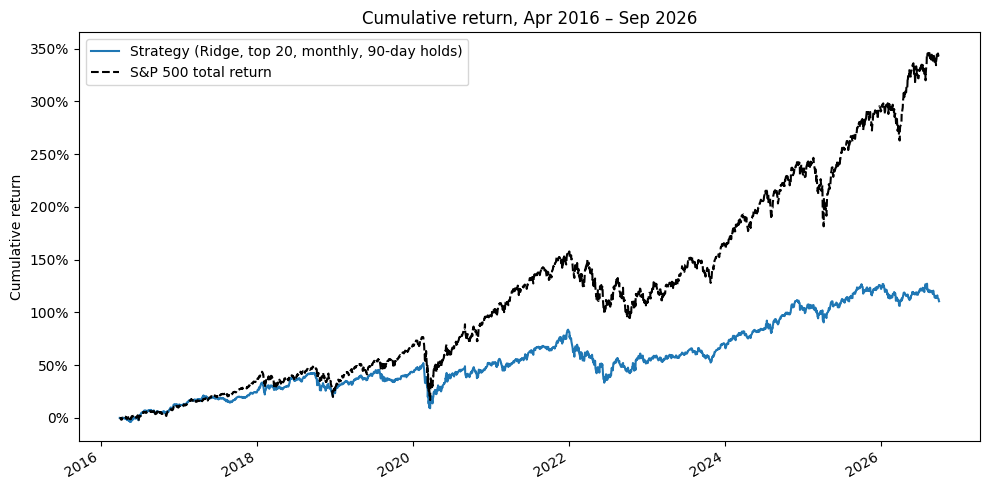

Beat the benchmark? False. Final value difference: $-2,296,622; CAGR difference: -7.81% per year


In [14]:
results = pd.DataFrame({"Strategy (Ridge top-%d)" % TOP_N: performance(hist.nav, CONFIG["risk_free"]),
                        "S&P 500 TR": performance(hist.benchmark_nav, CONFIG["risk_free"])})
results["difference"] = results.iloc[:, 0] - results.iloc[:, 1]
display(results.round(4))
results.to_csv(RESULTS / "performance.csv")

fig, ax = plt.subplots()
(hist.nav / CONFIG["initial_cash"] - 1).plot(ax=ax, label=f"Strategy (Ridge, top {TOP_N}, monthly, 90-day holds)")
(hist.benchmark_nav / CONFIG["initial_cash"] - 1).plot(ax=ax, label="S&P 500 total return", color="black", ls="--")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set(title="Cumulative return, Apr 2016 – Sep 2026", ylabel="Cumulative return", xlabel="")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "cumulative_returns.png", dpi=150)
plt.show()

beat = results.loc["final_value"].iloc[0] > results.loc["final_value"].iloc[1]
print(f"Beat the benchmark? {beat}. Final value difference: ${results.loc['final_value', 'difference']:,.0f}; "
      f"CAGR difference: {results.loc['CAGR', 'difference']:+.2%} per year")

## 7. Checks

In [15]:
trades = bt.trades
h = hist
checks = {}
# Cash: rebuild from the trade log and compare with the daily history.
rebuilt_cash = CONFIG["initial_cash"] + trades.groupby("date").cash_change.sum().reindex(h.index, fill_value=0).cumsum()
checks["cash rebuilt from trades == history cash"] = np.allclose(rebuilt_cash, h.cash, atol=1e-4)
checks["cash never negative"] = bool(h.cash.min() >= -1e-6)
checks["NAV == cash + holdings every day"] = np.allclose(h.cash + h.holdings, h.nav)
# PnL: realized + unrealized == NAV - initial capital.
open_lots = bt.open_lots
unrealized = (open_lots.market_value - open_lots.units * open_lots.entry_price - open_lots.entry_fee).sum()
checks["realized + unrealized PnL == NAV - 1,000,000"] = np.isclose(
    bt.account.realized_pnl + unrealized, h.nav.iloc[-1] - CONFIG["initial_cash"])
buys, sells = trades[trades.side == "BUY"], trades[trades.side == "SELL"]
# Timing.
checks["every buy fills after its signal close (next session)"] = bool(
    (buys.signal_date.map(calendar.get_loc) + 1 == buys.date.map(calendar.get_loc)).all())
checks["every buy is on the first session of a month"] = bool((buys.date.dt.month != buys.signal_date.dt.month).all())
checks["every sell is on/after its 90-day maturity"] = bool((sells.date >= sells.due_date).all())
checks["due date = entry + 90 calendar days"] = bool((trades.due_date - trades.entry_date == pd.Timedelta(days=90)).all())
checks["no trades outside the test window"] = bool(trades.date.between(test_start, test_end).all())
# Every score came from a model fitted on or before that signal date, using only matured labels.
checks["every model fit used only labels that ended before it scored"] = bool(
    (test_audit.last_label_end < test_audit.first_scored).all())
checks["scores used only on their own signal date"] = bool(test_scores.fit_date.le(test_scores.date).all())
# Purchases were in that quarter's universe.
membership = load_membership(DB_PATH, end=CONFIG["history_end"])
key = buys.assign(quarter_start=buys.date.dt.to_period("Q").dt.start_time)[["symbol", "quarter_start"]]
checks["every purchase was in its entry quarter's top-2000 list"] = bool(
    key.merge(membership[["symbol", "quarter_start"]], how="left", indicator=True)._merge.eq("both").all())
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values())

,passed
cash rebuilt from trades == history cash,True
cash never negative,True
NAV == cash + holdings every day,True
"realized + unrealized PnL == NAV - 1,000,000",True
every buy fills after its signal close (next session),True
every buy is on the first session of a month,True
every sell is on/after its 90-day maturity,True
due date = entry + 90 calendar days,True
no trades outside the test window,True
every model fit used only labels that ended before it scored,True


One real trade, recomputed by hand from the database:

In [16]:
lot_id = int(sells.lot_id.iloc[len(sells) // 2])
b, s = buys.set_index("lot_id").loc[lot_id], sells.set_index("lot_id").loc[lot_id]
with duckdb.connect(str(DB_PATH), read_only=True) as con:
    px = con.execute("SELECT date, adj_close FROM prices WHERE symbol=? AND date IN (?, ?)",
                     [b.symbol, b.date.date(), s.date.date()]).fetchdf()
print(f"Lot {lot_id}: {b.symbol}, signal {b.signal_date.date()}, bought {b.date.date()} at {b.price:.4f}, "
      f"due {b.due_date.date()}, sold {s.date.date()} at {s.price:.4f}")
display(px)
fee = CONFIG["fee_bps"] / 1e4
hand_pnl = b.units * s.price * (1 - fee) - (b.units * b.price * (1 + fee))
print(f"hand PnL {hand_pnl:,.2f} vs booked {s.realized_pnl:,.2f}")
assert np.isclose(hand_pnl, s.realized_pnl)
assert np.allclose(sorted(px.adj_close), sorted([b.price, s.price]))

Lot 1138: MC, signal 2021-03-31, bought 2021-04-01 at 44.0700, due 2021-06-30, sold 2021-06-30 at 46.7900


,date,adj_close
0,2021-04-01,44.07
1,2021-06-30,46.79


hand PnL 1,506.76 vs booked 1,506.76


## 8. Diagnostics, data gaps, and sensitivity

In [17]:
diag = pd.Series({
    "purchases": len(buys),
    "sales": len(sells),
    "distinct stocks bought": buys.symbol.nunique(),
    "average cash fraction of NAV": (h.cash / h.nav).iloc[1:].mean(),
    "total fees ($)": trades.fee.sum(),
    "buy orders rejected (no quote on fill day)": int(bt.events.event.eq("buy_rejected_no_quote").sum()),
    "unresolved price gaps (> 5 sessions)": int(bt.events.event.eq("unresolved_price_gap").sum()),
    "lots open at end": len(open_lots),
    "open lots without a 2026-09-30 quote": int(open_lots.last_quote.lt(test_end).sum()) if len(open_lots) else 0,
})
display(diag.to_frame("value"))
display(bt.events.loc[bt.events.event.ne("buy_rejected_no_quote")])

# Lots whose stock stopped trading and were never sold or were still unpriced at the end
gap_syms = set(bt.events.loc[bt.events.event.eq("unresolved_price_gap"), "symbol"])
stuck = open_lots.loc[open_lots.last_quote.lt(test_end)] if len(open_lots) else open_lots
display(stuck)
zero_recovery_nav = h.nav.iloc[-1] - (stuck.market_value.sum() if len(stuck) else 0.0)
print(f"Final NAV {h.nav.iloc[-1]:,.0f}; if every unpriced open lot were worth zero: {zero_recovery_nav:,.0f}")

,value
purchases,2338.000000
sales,2277.000000
distinct stocks bought,244.000000
average cash fraction of NAV,0.193457
total fees ($),49336.699777
buy orders rejected (no quote on fill day),2.000000
unresolved price gaps (> 5 sessions),12.000000
lots open at end,61.000000
open lots without a 2026-09-30 quote,21.000000


,date,symbol,event
1,2021-09-09,UZA,unresolved_price_gap
2,2022-07-13,CDK,unresolved_price_gap
4,2022-10-10,CHNG,unresolved_price_gap
5,2022-10-26,SHLX,unresolved_price_gap
6,2024-01-02,OXSQL,unresolved_price_gap
7,2024-03-26,SPLK,unresolved_price_gap
8,2025-02-25,FTAIO,unresolved_price_gap
9,2025-03-10,SBBA,unresolved_price_gap
10,2025-07-10,EVRI,unresolved_price_gap
11,2025-08-01,TGI,unresolved_price_gap


,lot_id,symbol,units,signal_date,entry_date,entry_price,entry_fee,due_date,last_mark,market_value,last_quote
0,1187,UZA,1052.387232,2021-06-30,2021-07-01,25.71,13.528438,2021-09-29,25.35,26678.016330,2021-08-31
1,1207,UZA,20.553071,2021-07-30,2021-08-02,25.33,0.260305,2021-10-31,25.35,521.020357,2021-08-31
2,1390,CDK,447.817082,2022-05-31,2022-06-01,54.52,12.207494,2022-08-30,54.76,24522.463405,2022-07-05
3,1406,CDK,396.151857,2022-06-30,2022-07-01,54.84,10.862484,2022-09-29,54.76,21693.275686,2022-07-05
4,1423,CHNG,1007.936930,2022-08-31,2022-09-01,24.75,12.473220,2022-11-30,27.49,27708.186199,2022-09-30
5,1426,SHLX,1577.889881,2022-08-31,2022-09-01,15.81,12.473220,2022-11-30,15.82,24962.217910,2022-10-18
6,1445,SHLX,1515.368936,2022-09-30,2022-10-03,15.82,11.986568,2023-01-01,15.82,23973.136574,2022-10-18
7,1645,OXSQL,38.044309,2023-09-29,2023-10-02,25.09,0.477266,2023-12-31,25.32,963.281901,2023-12-21
8,1663,OXSQL,1025.316545,2023-10-31,2023-11-01,24.97,12.801077,2024-01-30,25.32,25961.014911,2023-12-21
9,1681,OXSQL,1090.184469,2023-11-30,2023-12-01,25.23,13.752677,2024-02-29,25.32,27603.470745,2023-12-21


Final NAV 2,106,125; if every unpriced open lot were worth zero: 1,590,677


Best and worst trades, and the yearly comparison:

In [18]:
display(sells.nlargest(5, "realized_pnl")[["date", "symbol", "signal_date", "price", "realized_pnl"]])
display(sells.nsmallest(5, "realized_pnl")[["date", "symbol", "signal_date", "price", "realized_pnl"]])
yearly = pd.DataFrame({"strategy": h.nav.resample("YE").last().pct_change(),
                       "S&P 500 TR": h.benchmark_nav.resample("YE").last().pct_change()})
yearly.iloc[0] = [h.nav.resample("YE").last().iloc[0] / CONFIG["initial_cash"] - 1,
                  h.benchmark_nav.resample("YE").last().iloc[0] / CONFIG["initial_cash"] - 1]
yearly.index = yearly.index.year
display(yearly.round(3))
yearly.to_csv(RESULTS / "yearly_returns.csv")

,date,symbol,signal_date,price,realized_pnl
4021,2025-06-30,DAVE,2025-03-31,268.41,42073.300665
4602,2026-09-29,RNG,2026-06-30,74.43,29867.034022
3721,2024-10-30,APP,2024-07-31,171.65,28484.788994
4170,2025-10-30,UI,2025-07-31,770.73,28369.957682
4127,2025-09-29,APP,2025-06-30,712.36,26452.823452


,date,symbol,signal_date,price,realized_pnl
4598,2026-09-29,FICO,2026-06-30,617.869995,-17922.476202
4603,2026-09-29,APP,2026-06-30,305.660000,-16848.079657
1783,2020-04-01,FUN,2019-12-31,16.110000,-16366.602552
1798,2020-04-01,DENN,2019-12-31,7.280000,-15186.793848
1790,2020-04-01,SNBR,2019-12-31,17.740000,-15043.270912


,strategy,S&P 500 TR
date,,
2016,0.118,0.098
2017,0.109,0.218
2018,0.009,-0.044
2019,0.145,0.315
2020,0.052,0.184
2021,0.205,0.287
2022,-0.159,-0.181
2023,0.116,0.263
2024,0.187,0.250


The most frequently bought stocks and the sector mix of all purchases:

In [19]:
with duckdb.connect(str(DB_PATH), read_only=True) as con:
    names = con.execute("SELECT symbol, name FROM universe").fetchdf().set_index("symbol").name
most_bought = buys.symbol.value_counts().head(12).rename("purchases").to_frame()
most_bought["name"] = names.reindex(most_bought.index)
most_bought["sector"] = sectors.reindex(most_bought.index)
display(most_bought)
display(buys.symbol.map(sectors).value_counts(normalize=True).round(3).rename("share of purchases").to_frame())

,purchases,name,sector
symbol,,,
DPZ,115,"Domino's Pizza, Inc.",Consumer Cyclical
VRSN,110,"VeriSign, Inc.",Technology
YUM,95,"Yum! Brands, Inc.",Consumer Cyclical
WINA,72,Winmark Corporation,Consumer Cyclical
TXN,66,Texas Instruments Incorporated,Technology
FICO,64,Fair Isaac Corporation,Technology
AAPL,60,Apple Inc.,Technology
UI,54,Ubiquiti Inc.,Technology
MCD,45,McDonald's Corporation,Consumer Cyclical


,share of purchases
symbol,
Consumer Cyclical,0.325
Technology,0.304
Financial Services,0.101
Healthcare,0.099
Industrials,0.057
Consumer Defensive,0.052
Communication Services,0.024
Energy,0.015
Basic Materials,0.012


Transaction-cost sensitivity: rerun the same forecasts with 0 and 25 bps per side.

In [20]:
cost_rows = []
for bps in [0, CONFIG["fee_bps"], 25]:
    b2 = Backtester(quotes, to_score_dict(test_scores), top_n=TOP_N, cohort_fraction=CONFIG["cohort_fraction"],
                    holding_days=CONFIG["holding_days"], initial_cash=CONFIG["initial_cash"], fee_bps=bps)
    perf = performance(b2.run(test_start, test_end).nav, CONFIG["risk_free"])
    cost_rows.append({"fee_bps": bps, **perf[["final_value", "CAGR", "max_drawdown", "Sharpe"]].to_dict()})
display(pd.DataFrame(cost_rows).set_index("fee_bps"))

# Forecast quality in the test period (only rows whose targets are known)
evaluation = panel[["date", "symbol", "target"]].merge(test_scores, on=["date", "symbol"]).dropna(subset=["target"])
display(prediction_metrics(evaluation, evaluation.score).to_frame("test-period forecast metrics"))

,final_value,CAGR,max_drawdown,Sharpe
fee_bps,,,,
0,2.174972e+06,0.076811,-0.281650,0.465234
5,2.106125e+06,0.073517,-0.281727,0.442908
25,1.852108e+06,0.060457,-0.282039,0.353557


,test-period forecast metrics
RMSE,0.239851
MAE,0.150613
R2,-0.025891
mean_daily_rank_IC,0.037444
IC_dates,124.000000


## 9. Findings

### Did I beat the benchmark?

No. From April 1, 2016 to September 30, 2026 the strategy grew $1,000,000 to about $2.11 million (7.4% CAGR, Sharpe 0.44), while the S&P 500 total-return index grew it to about $4.40 million (15.2% CAGR, Sharpe 0.77). Shortfall of roughly $2.3 million / 7.8 percentage points per year. The strategy was less volatile (13.7% vs 17.8%) and had a smaller maximum drawdown (−28.2% vs −33.8%). By calendar year it beat the index only in 2016, 2018, and 2022, all weak years for the market.

### Why?

1. The forecasts held up, but the edge is small and spread over 2,000 stocks. The test-period rank IC (+0.037) is about what development predicted (+0.034), so the model did not fall apart out of sample. But an IC this small says little about which 20 stocks will do best. The model mostly rewards high profitability and free cash flow and penalizes volatility, so it bought steady "quality" companies (Domino's, VeriSign, Yum!, McDonald's, Home Depot, Texas Instruments). Those did fine, but 2016–2026 was dominated by a few fast-growing mega-cap tech stocks that make up much of the cap-weighted index, and a low-volatility tilt systematically under-owns them.
2. On average about 19% of the portfolio was in cash earning 0%. With the index returning ~15% a year, that alone costs roughly 2–3 percentage points per year.
3. 12 holdings lost their price history mid-holding (for example CDK, CHNG, SPLK, SHLX, EVRI). Following my policy, these 21 lots (about $0.52 million at their last marks) are never sold, so that capital was never reinvested.
4. Costs were modest: about $49,000 in fees at 5 bps per side. At 25 bps per side the CAGR drops from 7.4% to 6.0%.

### Risks and limitations

* If the 21 lots without a final quote were worth zero, the final value would fall from $2.11 million to about $1.59 million. The truth is probably close to the last mark for the acquisitions, but there is no delisting-proceeds table, so I report both numbers rather than invent a fill.
* Data: Prices and shares have inconsistent adjustments, financial data are the vendor's latest restated values rather than what was known at the time, and sectors are today's labels. Quarterly membership removes deliberate survivorship bias, but the guide warns it is not certified point-in-time data.
* Concentration: 20 names per monthly cohort (~60 open lots) with a strong tilt to consumer cyclical and technology. There weren't any sector limits.
* Execution: fills at the exact adjusted close, fractional units, no market impact, and no tax.
* Single test path: one 10-year path with one set of choices.

### Unsuccessful ideas and what I'd try next

* Raw-return target (failed): the lecture's raw 90-day return gave a negative development IC for every alpha. Training on same-day percentile ranks fixed this, and it was a useful change.
* Alpha made little difference, because millions of training rows overwhelm the penalty and only very large values (10^6) changed the fit noticeably.
* Next experiments:
  1. Put cash to work when lots mature, for example by also buying on the session after a sale instead of waiting for the next month.
  2. A nonlinear model (`HistGradientBoostingRegressor`) to capture interactions such as "momentum only matters for profitable firms."
  3. Remove the low-volatility bias, e.g. rank within sectors or neutralize the volatility exposure, so the portfolio is less defensive than the market.
  4. A clearer missing-price policy, such as treating an acquisition at its last price as cash after a fixed delay, documented as an assumption.